# Lab 3 – Khám phá dữ liệu (EDA) và PCA cho IMDb

Notebook này bổ sung bước khám phá dữ liệu trước khi fine-tune DistilBERT. Notebook **không huấn luyện lại mô hình** và không thay đổi hai notebook Exercise 1, Exercise 2 hiện có.

**Phạm vi thực hiện**
- Nguồn dữ liệu: `stanfordnlp/imdb`, split `train` gốc.
- EDA: kiểm tra kích thước, nhãn, dữ liệu thiếu/trùng lặp và độ dài review.
- PCA: lấy mẫu phân tầng 1.000 review (500 NEGATIVE, 500 POSITIVE) từ tập train; chuyển văn bản thành TF-IDF rồi giảm chiều về 2 thành phần bằng PCA.
- Không sử dụng tập test trong EDA/PCA để tránh đưa dữ liệu đánh giá cuối vào bước khám phá.

**Lưu ý:** PCA ở đây chạy trên đặc trưng TF-IDF của văn bản, không phải embedding của mô hình đã fine-tune. Đây là phân tích khám phá dữ liệu, không phải bước huấn luyện phân loại.

## 1. Chuẩn bị thư viện và cấu hình

In [13]:
import sys
import subprocess

print("Python đang sử dụng:", sys.executable)

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "datasets==3.3.2"
])

print("Cai dat datasets thanh cong!")

Python đang sử dụng: c:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe
Cai dat datasets thanh cong!


In [14]:
from pathlib import Path
import html
import re
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

SEED = 42
OUTPUT_DIR = Path("outputs/eda_pca")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Output directory:", OUTPUT_DIR.resolve())

Python: 3.10.11
Pandas: 2.3.3
NumPy: 1.26.4
Output directory: D:\Deep Learning\Lab3_DL_Group4-main\Lab3_DL_Group4-main\outputs\eda_pca


## 2. Tải và kiểm tra dữ liệu gốc

In [15]:
# Dùng đúng nguồn dữ liệu đã được sử dụng trong Exercise 2.
raw_train = load_dataset("stanfordnlp/imdb", split="train")
df = raw_train.to_pandas()

label_names = {0: "NEGATIVE", 1: "POSITIVE"}
df["label_name"] = df["label"].map(label_names)

print("Dataset source: stanfordnlp/imdb")
print("Split: train")
print("Number of rows:", len(df))
print("Columns:", df.columns.tolist())
print("\nLabel counts:")
print(df["label_name"].value_counts().sort_index())
print("\nMissing values:")
print(df[["text", "label"]].isna().sum())
print("\nDuplicated review texts:", int(df["text"].duplicated().sum()))

assert set(df["label"].dropna().unique()) == {0, 1}
assert df["text"].notna().all(), "Có review bị thiếu text; cần kiểm tra trước khi tiếp tục."

Dataset source: stanfordnlp/imdb
Split: train
Number of rows: 25000
Columns: ['text', 'label', 'label_name']

Label counts:
label_name
NEGATIVE    12500
POSITIVE    12500
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Duplicated review texts: 96


## 3. Làm sạch nhẹ và thống kê độ dài review

Chỉ loại bỏ thẻ HTML và chuẩn hóa khoảng trắng để thống kê độ dài dễ nhất quán. Văn bản gốc vẫn được giữ nguyên trong cột `text`; bước này không thay đổi dữ liệu dùng cho fine-tuning cũ.

In [16]:
def clean_review_for_eda(text):
    text = html.unescape(str(text))
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].map(clean_review_for_eda)
df["word_count"] = df["clean_text"].str.split().str.len()
df["char_count"] = df["clean_text"].str.len()

length_summary = (
    df.groupby("label_name")[["word_count", "char_count"]]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
)
display(length_summary)

summary_rows = []
for label, group in df.groupby("label_name"):
    summary_rows.append({
        "label": label,
        "samples": int(len(group)),
        "mean_words": float(group["word_count"].mean()),
        "median_words": float(group["word_count"].median()),
        "mean_characters": float(group["char_count"].mean()),
        "missing_text": int(group["text"].isna().sum()),
        "duplicate_texts": int(group["text"].duplicated().sum()),
    })

eda_summary = pd.DataFrame(summary_rows)
eda_summary.to_csv(OUTPUT_DIR / "eda_summary_by_class.csv", index=False, encoding="utf-8-sig")
print("Saved:", OUTPUT_DIR / "eda_summary_by_class.csv")

word_count                                  char_count           \
                count    mean median     std min   max      count     mean   
label_name                                                                   
NEGATIVE        12500  228.49  173.0  164.87  10  1491      12500  1279.51   
POSITIVE        12500  234.49  172.0  178.78  12  2459      12500  1325.22   

                                       
           median      std min    max  
label_name                             
NEGATIVE    959.0   939.33  52   8698  
POSITIVE    968.0  1029.76  70  13593

Saved: outputs\eda_pca\eda_summary_by_class.csv


## 4. Trực quan hóa phân bố nhãn

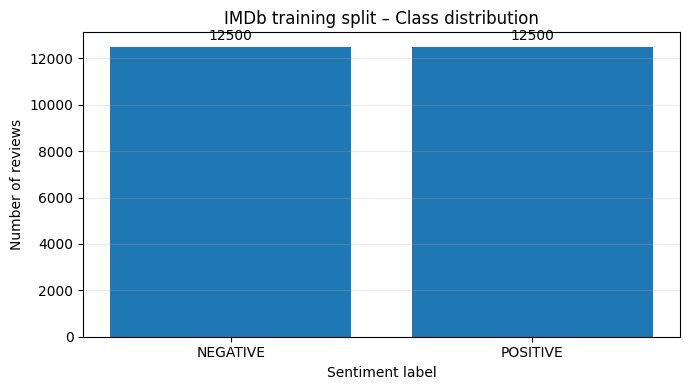

Class proportions:
label_name
NEGATIVE    0.5
POSITIVE    0.5
Name: count, dtype: float64


In [17]:
label_counts = df["label_name"].value_counts().reindex(["NEGATIVE", "POSITIVE"])

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(label_counts.index, label_counts.values)
ax.set_title("IMDb training split – Class distribution")
ax.set_xlabel("Sentiment label")
ax.set_ylabel("Number of reviews")
ax.bar_label(bars, padding=3)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Class proportions:")
print((label_counts / label_counts.sum()).round(4))

## 5. Trực quan hóa độ dài review

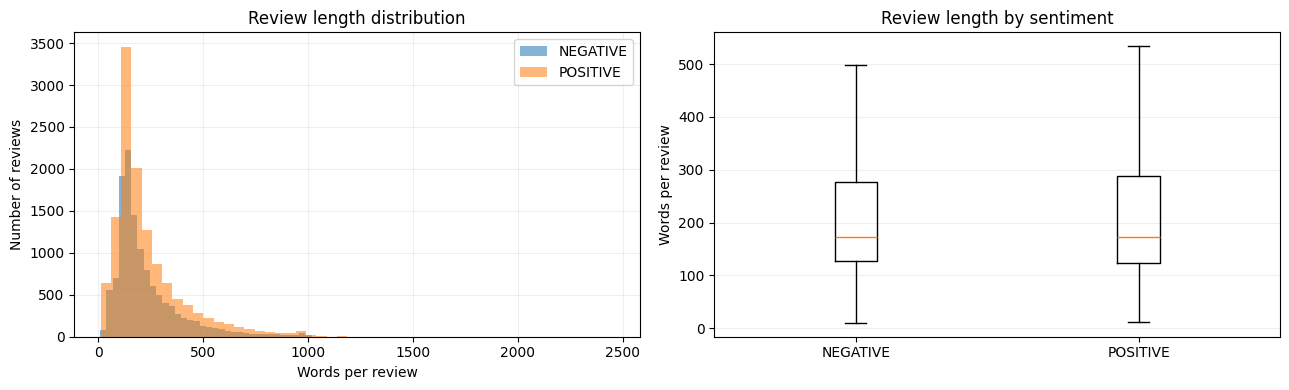

Overall word-count summary:
count    25000.00
mean       231.49
std        171.99
min         10.00
25%        126.00
50%        173.00
75%        281.00
max       2459.00
Name: word_count, dtype: float64


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = {"NEGATIVE": "tab:blue", "POSITIVE": "tab:orange"}

for label in ["NEGATIVE", "POSITIVE"]:
    values = df.loc[df["label_name"] == label, "word_count"]
    axes[0].hist(values, bins=50, alpha=0.55, label=label, color=colors[label])

axes[0].set_title("Review length distribution")
axes[0].set_xlabel("Words per review")
axes[0].set_ylabel("Number of reviews")
axes[0].legend()
axes[0].grid(alpha=0.2)

box_data = [
    df.loc[df["label_name"] == label, "word_count"].values
    for label in ["NEGATIVE", "POSITIVE"]
]
axes[1].boxplot(box_data, showfliers=False)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["NEGATIVE", "POSITIVE"])
axes[1].set_title("Review length by sentiment")
axes[1].set_ylabel("Words per review")
axes[1].grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "review_length_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Overall word-count summary:")
print(df["word_count"].describe().round(2))

## 6. Lấy mẫu phân tầng để thực hiện PCA

Để PCA chạy ổn định trên máy CPU, notebook lấy 500 review mỗi lớp từ split train gốc. Việc lấy mẫu chỉ phục vụ trực quan hóa; không thay đổi tập train/validation/test của Exercise 2.

In [19]:
pca_sample = (
    df.groupby("label", group_keys=False)
      .sample(n=500, random_state=SEED)
      .sample(frac=1, random_state=SEED)
      .reset_index(drop=True)
)
pca_sample["label_name"] = pca_sample["label"].map(label_names)

print("PCA sample size:", len(pca_sample))
print(pca_sample["label_name"].value_counts().sort_index())
assert len(pca_sample) == 1000
assert pca_sample["label"].value_counts().to_dict() == {0: 500, 1: 500}

PCA sample size: 1000
label_name
NEGATIVE    500
POSITIVE    500
Name: count, dtype: int64


## 7. Chuyển văn bản thành TF-IDF và giảm chiều bằng PCA

TF-IDF biểu diễn mỗi review thành vector đặc trưng từ vựng. PCA được áp dụng trên ma trận TF-IDF đã chuyển sang dạng dense của 1.000 mẫu (tối đa 1.000 đặc trưng), nên mức sử dụng bộ nhớ phù hợp với bài thực hành nhỏ.

In [20]:
tfidf = TfidfVectorizer(
    max_features=1000,
    min_df=3,
    max_df=0.95,
    stop_words="english",
    sublinear_tf=True,
)

X_tfidf_sparse = tfidf.fit_transform(pca_sample["clean_text"])
X_tfidf = X_tfidf_sparse.toarray()

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary features:", len(tfidf.get_feature_names_out()))

pca = PCA(n_components=2, svd_solver="randomized", random_state=SEED)
X_pca = pca.fit_transform(X_tfidf)

explained = pca.explained_variance_ratio_
print(f"PC1 explained variance: {explained[0]:.4%}")
print(f"PC2 explained variance: {explained[1]:.4%}")
print(f"Cumulative explained variance (2 PCs): {explained.sum():.4%}")

pca_results = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "label": pca_sample["label"].to_numpy(),
    "label_name": pca_sample["label_name"].to_numpy(),
})
pca_results.to_csv(OUTPUT_DIR / "pca_coordinates.csv", index=False, encoding="utf-8-sig")

pca_metadata = {
    "source": "stanfordnlp/imdb",
    "split": "train",
    "sample_size": int(len(pca_sample)),
    "samples_per_class": 500,
    "representation": "TF-IDF",
    "max_features": 1000,
    "pca_components": 2,
    "explained_variance_ratio": [float(x) for x in explained],
    "cumulative_explained_variance": float(explained.sum()),
    "random_seed": SEED,
}
with (OUTPUT_DIR / "pca_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(pca_metadata, f, indent=2, ensure_ascii=False)
print("Saved PCA coordinates and metadata to", OUTPUT_DIR)

TF-IDF matrix shape: (1000, 1000)
Vocabulary features: 1000
PC1 explained variance: 0.9781%
PC2 explained variance: 0.7144%
Cumulative explained variance (2 PCs): 1.6925%
Saved PCA coordinates and metadata to outputs\eda_pca


## 8. Biểu đồ PCA 2D

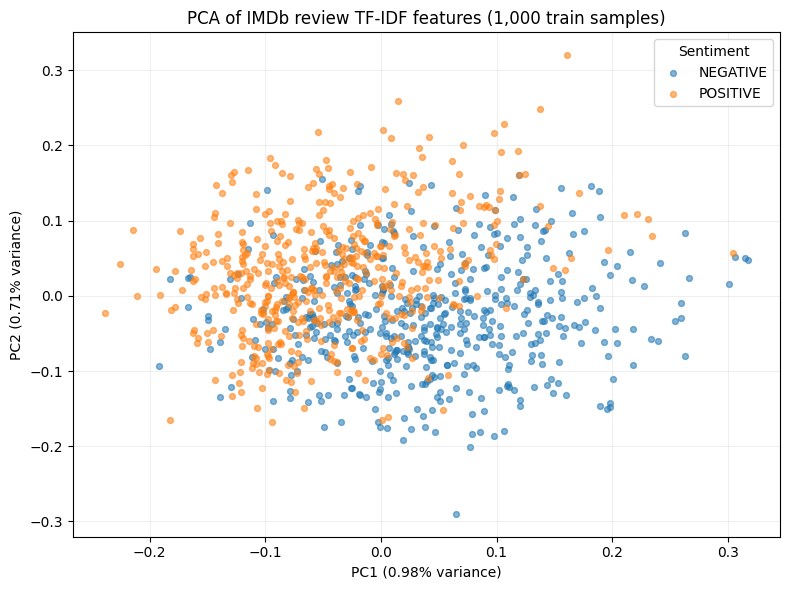

In [21]:
fig, ax = plt.subplots(figsize=(8, 6))
for label in ["NEGATIVE", "POSITIVE"]:
    mask = pca_results["label_name"] == label
    ax.scatter(
        pca_results.loc[mask, "PC1"],
        pca_results.loc[mask, "PC2"],
        s=18,
        alpha=0.55,
        label=label,
    )

ax.set_title("PCA of IMDb review TF-IDF features (1,000 train samples)")
ax.set_xlabel(f"PC1 ({explained[0]:.2%} variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.2%} variance)")
ax.legend(title="Sentiment")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pca_visualization.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

## 9. Nhận xét kết quả EDA/PCA

Sau khi chạy notebook, điền nhận xét dựa trên các biểu đồ và số liệu thực tế:

1. Hai lớp trong tập train có số lượng bằng nhau hay không? Dẫn số liệu từ bảng phân bố nhãn.
2. Review NEGATIVE và POSITIVE có độ dài trung bình/trung vị khác nhau không? Dẫn số liệu từ `eda_summary_by_class.csv`.
3. Có bao nhiêu review bị trùng lặp? Có giá trị thiếu hay không?
4. Hai thành phần PCA giải thích tổng cộng bao nhiêu phần trăm phương sai?
5. Trên biểu đồ PCA, hai lớp có tách biệt rõ hay còn chồng lấn? Không kết luận rằng PCA chứng minh mô hình phân loại tốt; đây chỉ là phép chiếu 2D để quan sát dữ liệu.

**Giới hạn:** PCA chỉ giữ hai thành phần nên phần lớn thông tin có thể không được thể hiện trên biểu đồ. Kết quả phụ thuộc vào mẫu 1.000 review và cách biểu diễn TF-IDF.

## 10. Kết luận và phạm vi ảnh hưởng đến thực nghiệm cũ

Notebook này chỉ tải và phân tích split train gốc của IMDb, tạo biểu đồ và file thống kê trong `outputs/eda_pca/`. Không gọi `Trainer`, không cập nhật tham số DistilBERT, không thay đổi checkpoint và không chạy lại fine-tuning. Kết quả EDA/PCA cần được chạy và lưu output trên máy của nhóm trước khi đưa vào báo cáo chính thức.